In [1]:
!which python
!hostname
!pwd

/nfs/turbo/coe-venkvis/ziqiw-turbo/conda/agent2/bin/python


lh1702.arc-ts.umich.edu
/nfs/turbo/coe-venkvis/ziqiw-turbo/v2


# Imports

In [2]:
import sys
sys.path.append("/nfs/turbo/coe-venkvis/ziqiw-turbo/material_agent/GNoME_DREAMS_OER_screening/src/GNoME_DREAMS_OER_screening")
import numpy as np

from ase.io import read, Trajectory
from ase.visualize import view
from pymatgen.io.ase import AseAtomsAdaptor

from oer.OER_study import OER_catalyst_study

import seaborn as sns
sns_colors = sns.color_palette("tab10")

# Rutile TiO2 used for testing:
TiO2 = read("/nfs/turbo/coe-venkvis/ziqiw-turbo/material_agent/GNoME_DREAMS_OER_screening/notebooks/TiO2_rutile.cif")
TiO2_structure = AseAtomsAdaptor.get_structure(TiO2)

# Example GNoME structures contaning Ir:
test_cands = Trajectory('/nfs/turbo/coe-venkvis/ziqiw-turbo/material_agent/GNoME_DREAMS_OER_screening/notebooks/test_cands.traj')
if False:
    view(test_cands)

## Short Overview of Intented Usage:


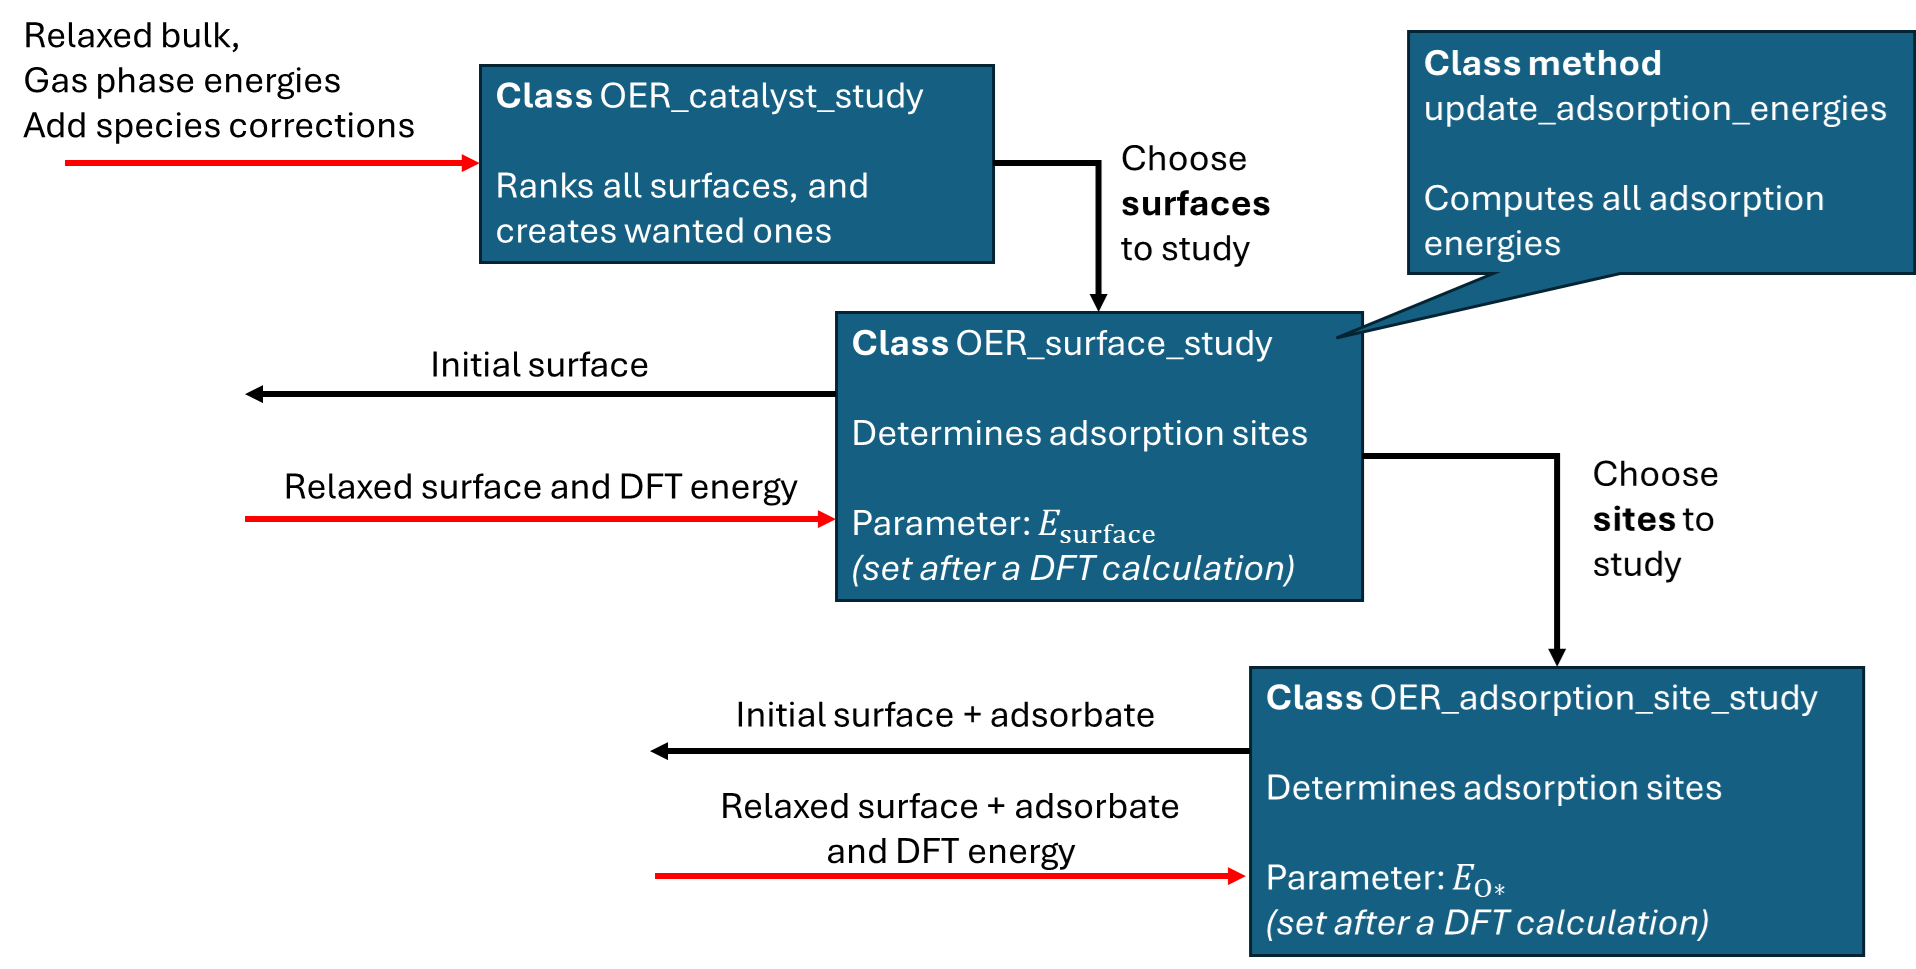
Illustration of intented usage


Before using this code, you would need:
1. The DFT energy of relaxed and isolated H2 and H2O molecyles. 
2. The DFT relaxed bulk structure.

Then this code sould be used as follows:
1. Make `OER_surface_study` object with bulk structure obtained from the relaxation: `OER_catalyst_study(ASE Atoms object)`
2. Identify distinct surfaces (i.e., surfaces that are symmetrically in-equivalent), via the method `OER_surface_study.identify_distinct_surfaces(max_miller)` where you can choose an appropriate max miller index (method may be unstable for large indecies).
3. Rank these surfaces via the method `OER_surface_study.predict_most_likely_surfaces()`.
4. For every surface that you want to investegate futher, you must initialize them by using the method: `OER_surface_study.initialize_OER_surface_studies( tuble(int,int,int) )`. This initializes one or more `OER_surface_study` objects of this surface, which are stored in the `OER_surface_study` object. As many terminations may be possible for a given lattice direction (defined by the miller indecies) all are created in the initilization.
5. Perform a DFT relaxation of a termination by first getting it as an atoms object via `atoms = OER_surface_study.get_non_relaxed_surface()` and store the result via `OER_surface_study.set_relaxed_surface_with_O(relaxed_atoms)`
6. Determine adsorbtion sites for this surface  `OER_surface_study.determine_adsorption_sites()`
7. Inilitialize one or more of these sites via `OER_surface_study.initialize_adsorption_site_study`, which stores a new `OER_adsorption_site_study` object in the `OER_surface_study` object.
8. Perform a DFT relaxation of the surface + O-adsorbate by getting the atoms object from `atoms = OER_adsorption_site_study.get_initial_surface_with_O()` and then store the result in the object: `OER_adsorption_site_study.set_relaxed_surface_with_O(relaxed_atoms)`.
9. You can now run `OER_surface_study.update_adsorption_energies()` to compute the adsorbtion energy, and display it by getting the pandas df `sur_study.get_adsorption_sites_df()`.


A example of how to use the code is given below:

1. Make `OER_surface_study` object

In [3]:
# Choose an bulk structure:

# atoms = TiO2 # TiO2 is an Ase Atoms object
atoms = test_cands[1] # Select a candidate from the trajectory (all of these are from the GNoME database)

# Initialize the OER catalyst study:
catalyst_study = OER_catalyst_study(
    bulk = atoms, 
    H2O_gas_free_energy = -14.217, # <--- should be the DFT energy + free energy corrections, at the relevant level of theory
    H2_gas_free_energy = -6.77, # <--- should be the DFT energy + free energy corrections, at the relevant level of theory
                                    )

2. Identify distinct surfaces

In [4]:
catalyst_study.identify_distinct_surfaces(max_miller = 1)
catalyst_study.get_df_with_surface_rankings() # <--- gives the dataframe with the surface

,miller_indices
0,"(1, 1, 1)"
1,"(1, 1, 0)"
2,"(1, 0, 1)"
3,"(1, 0, 0)"
4,"(0, 0, 1)"


3. Rank these surfaces

In [5]:
catalyst_study.predict_most_likely_surfaces(method = 'coordination', stoichiometry='stoichiometric') # An method should be chosen
catalyst_study.get_df_with_surface_rankings().sort_values(by='Normalized Score', ascending=False)
# Higher Normalized Score means more likely surface

,miller_indices,Score,Normalized Score
1,"(1, 1, 0)",-0.099772,1.000000
3,"(1, 0, 0)",-0.141099,0.782062
0,"(1, 1, 1)",-0.188647,0.531313
2,"(1, 0, 1)",-0.211379,0.411438
4,"(0, 0, 1)",-0.289398,0.000000


4. Initialize surface

In [6]:
catalyst_study.initialize_OER_surface_studies((1,1,0))
surface_study_dict = catalyst_study.get_surface_studies() # dict with miller as key and list of surface studies as value

In [7]:
print(len(surface_study_dict[(1,1,0)]), " surfaces constructed for the (1,1,0) miller index.")
surface_study_dict

2  surfaces constructed for the (1,1,0) miller index.


{(1, 1, 0): (<oer.OER_surface_study.OER_surface_study at 0x154fd6ea5510>,
  <oer.OER_surface_study.OER_surface_study at 0x154fc56a2710>)}

At this point, you can obtain a list of adsorption sites for a given surface, but the surface should be relaxed before proceeding to adsorption calculations. This step is only meant to provide an initial overview of possible adsorption sites.

In [8]:
sur_study = surface_study_dict[(1,1,0)][0] # Get the frist termination of the (1,1,0) surfaces

# use_relaxed_surface = False, Sould only be used if the surface has not been relaxed yet.
# Initialization of adsorption sites is only intended on sites found on the relaxed surface.

sur_study.determine_adsorption_sites(
    use_relaxed_surface = False
    )
sur_study.get_adsorption_sites_df(relaxed_surface = False)
# For now only determining "on-top" adsorption sites

,site type,add site element,position,G(O),G(O),G(OH),G(OH),G(OOH),G(OOH)
0,on-top,Ni,"[0.6226088229294655, 7.787577970512002, 18.340...",None,None,None,None,None,None
1,on-top,Ni,"[3.8422887363078893, 3.1180719705119997, 18.34...",None,None,None,None,None,None
2,on-top,Ir,"[0.6226088229294656, 4.680516695148, 18.510918...",None,None,None,None,None,None
3,on-top,Ir,"[3.8422887363078893, 0.011010695148000257, 18....",None,None,None,None,None,None
4,on-top,Rh,"[0.6226088229294658, 1.5398349765839998, 18.52...",None,None,None,None,None,None
5,on-top,Rh,"[3.842288736307889, 6.2093409765839995, 18.520...",None,None,None,None,None,None


In [9]:
# You can view the surface with all identified adsorption sites like this:
sur_study.view_base_surface(
    relaxed_surface = False,
    include_adsorption_sites = True
)

usage: ase [-h] [--version] [-T]
           {help,info,test,gui,db,run,band-structure,build,dimensionality,eos,ulm,find,nebplot,nomad-upload,nomad-get,convert,reciprocal,completion,diff,exec}
           ...
ase: error: TclError: no display name and no $DISPLAY environment variable
To get a full traceback, use: ase -T gui ...


5. Perform a DFT relaxation of a termination

In [9]:
atoms = sur_study.get_non_relaxed_surface()

relaxed_atoms = atoms.copy() # Fake relaxed structure for testing purposes
sur_study.set_relaxed_base_surface(relaxed_atoms, energy = -100.0)

6. Determine adsorbtion sites (Now for the relaxed surface)

In [10]:

sur_study.determine_adsorption_sites(use_relaxed_surface = True)
sur_study.get_adsorption_sites_df()

,site type,add site element,position,G(O),G(O),G(OH),G(OH),G(OOH),G(OOH)
0,on-top,Ni,"[0.6226088229294664, 7.787577970512001, 18.340...",None,None,None,None,None,None
1,on-top,Ni,"[3.8422887363078897, 3.1180719705119997, 18.34...",None,None,None,None,None,None
2,on-top,Ir,"[0.622608822929466, 4.680516695148001, 18.5109...",None,None,None,None,None,None
3,on-top,Ir,"[3.8422887363078893, 0.011010695148000257, 18....",None,None,None,None,None,None
4,on-top,Rh,"[0.6226088229294654, 1.5398349765839985, 18.52...",None,None,None,None,None,None
5,on-top,Rh,"[3.84228873630789, 6.2093409765839995, 18.5209...",None,None,None,None,None,None


7. Inilitialize `OER_adsorption_site_study` for a given site, via its index in the above df

In [11]:
sur_study.initialize_adsorption_site_study(0) # Initialize an adsorption site study for adsorption site with index 0
sur_sites_dict = sur_study.get_adsorption_site_studies_dict() # dict with site index as key and adsorption site study as value
sur_sites_dict

{0: <GNoME_DREAMS_OER_screening.OER.OER_adsorption_site_study.OER_adsorption_site_study at 0x232a63a9d30>}

8. Perform a DFT relaxation of the surface + O-adsorbate

In [12]:
surface_O = sur_sites_dict[0].get_initial_surface_with_O()

In [13]:
# You can view the surface with the O-adsorbate. The adsorbate has tag set to 1 - press "c" in the viewer and set color to: By tag
if False:
    view(surface_O)

In [14]:
sur_sites_dict[0].set_relaxed_surface_with_O(surface_O, energy = -105.0)

9. Run `OER_surface_study.update_adsorption_energies()`

In [15]:
sur_study.update_adsorption_energies()
sur_study.get_adsorption_sites_df()

,site type,add site element,position,G(O),G(O),G(OH),G(OH),G(OOH),G(OOH)
0,on-top,Ni,"[0.6226088229294664, 7.787577970512001, 18.340...",2.517,None,None,None,None,None
1,on-top,Ni,"[3.8422887363078897, 3.1180719705119997, 18.34...",None,None,None,None,None,None
2,on-top,Ir,"[0.622608822929466, 4.680516695148001, 18.5109...",None,None,None,None,None,None
3,on-top,Ir,"[3.8422887363078893, 0.011010695148000257, 18....",None,None,None,None,None,None
4,on-top,Rh,"[0.6226088229294654, 1.5398349765839985, 18.52...",None,None,None,None,None,None
5,on-top,Rh,"[3.84228873630789, 6.2093409765839995, 18.5209...",None,None,None,None,None,None


### Ideally, the could would be used more like seen in the cell below:

In [16]:
sites_df = sur_study.get_adsorption_sites_df()
site_studies_dict = sur_study.get_adsorption_site_studies_dict()

for index, row in sites_df.iterrows():

    # Skip initialized sites:
    if index in site_studies_dict:
        continue

    # Initialize other sites:
    sur_study.initialize_adsorption_site_study(index)

list_of_atoms_to_relax = []
for site_index, site_study in site_studies_dict.items():

    adsorbed_energies_dict = site_study.get_adsorption_site_energies()
    if adsorbed_energies_dict['O_adsorbed_energy'] is not None:
        continue

    list_of_atoms_to_relax.append(
        [site_index, site_study.get_initial_surface_with_O()]
        )
    
for site_index, atoms in list_of_atoms_to_relax:
    # Here you would normally relax the structure and get the energy
    # For testing purposes we just set a fake energy
    fake_energy = -104 - 2*np.random.rand()

    site_studies_dict[site_index].set_relaxed_surface_with_O(
        atoms, energy = fake_energy
        )
    
sur_study.update_adsorption_energies()
sur_study.get_adsorption_sites_df()




,site type,add site element,position,G(O),G(O),G(OH),G(OH),G(OOH),G(OOH)
0,on-top,Ni,"[0.6226088229294664, 7.787577970512001, 18.340...",2.517,None,None,None,None,None
1,on-top,Ni,"[3.8422887363078897, 3.1180719705119997, 18.34...",1.770901,None,None,None,None,None
2,on-top,Ir,"[0.622608822929466, 4.680516695148001, 18.5109...",2.50485,None,None,None,None,None
3,on-top,Ir,"[3.8422887363078893, 0.011010695148000257, 18....",1.966897,None,None,None,None,None
4,on-top,Rh,"[0.6226088229294654, 1.5398349765839985, 18.52...",2.325715,None,None,None,None,None
5,on-top,Rh,"[3.84228873630789, 6.2093409765839995, 18.5209...",2.814826,None,None,None,None,None
